In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

pd.set_option("display.max_colwidth", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

In [3]:
print("ORDERS:", orders.columns.tolist())
print("ITEMS:", items.columns.tolist())
print("PRODUCTS:", products.columns.tolist())
print("CUSTOMERS:", customers.columns.tolist())
print("PAYMENTS:", payments.columns.tolist())

ORDERS: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
ITEMS: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
PRODUCTS: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
CUSTOMERS: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
PAYMENTS: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [4]:
print("Orders:", orders.shape)
print("Order Items:", items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)

Orders: (99441, 8)
Order Items: (112650, 7)
Products: (32951, 9)
Customers: (99441, 5)
Payments: (103886, 5)


In [5]:
# DATASET OVERVIEW: size, content and basic quality of each raw table

tables = {
    "Orders": orders,
    "Order Items": items,
    "Products": products,
    "Customers": customers,
    "Payments": payments,
}

overview = pd.DataFrame({
    "Table": list(tables.keys()),
    "Rows": [df.shape[0] for df in tables.values()],
    "Columns": [df.shape[1] for df in tables.values()],
    "Missing values": [int(df.isnull().sum().sum()) for df in tables.values()],
    "Duplicate rows": [int(df.duplicated().sum()) for df in tables.values()],
    "Contains": [
        "Order status and timestamps",
        "Items, prices and freight per order",
        "Product category and attributes",
        "Customer ID, city and state",
        "Payment type, instalments and value",
    ],
})
overview

,Table,Rows,Columns,Missing values,Duplicate rows,Contains
0,Orders,99441,8,4908,0,Order status and timestamps
1,Order Items,112650,7,0,0,"Items, prices and freight per order"
2,Products,32951,9,2448,0,Product category and attributes
3,Customers,99441,5,0,0,"Customer ID, city and state"
4,Payments,103886,5,0,0,"Payment type, instalments and value"


In [6]:
print("ORDERS - Missing Values")
print(orders.isnull().sum())

print("\nORDER ITEMS - Missing Values")
print(items.isnull().sum())

print("\nPRODUCTS - Missing Values")
print(products.isnull().sum())

print("\nCUSTOMERS - Missing Values")
print(customers.isnull().sum())

print("\nPAYMENTS - Missing Values")
print(payments.isnull().sum())

ORDERS - Missing Values
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

ORDER ITEMS - Missing Values
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

PRODUCTS - Missing Values
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

CUSTOMERS - Missing Values
customer_id                 0
customer_unique_id          0
custome

In [7]:
# MISSING VALUE REPORT: only columns that have missing values (raw data)

missing_rows = []
for name, df in tables.items():
    for col in df.columns:
        count = df[col].isnull().sum()
        if count > 0:
            missing_rows.append({
                "Table": name,
                "Column": col,
                "Missing": int(count),
                "Missing %": round(count / len(df) * 100, 2),
            })

no_missing = [name for name, df in tables.items() if df.isnull().sum().sum() == 0]
print("Tables with no missing values:", ", ".join(no_missing))

pd.DataFrame(missing_rows)

Tables with no missing values: Order Items, Customers, Payments


,Table,Column,Missing,Missing %
0,Orders,order_approved_at,160,0.16
1,Orders,order_delivered_carrier_date,1783,1.79
2,Orders,order_delivered_customer_date,2965,2.98
3,Products,product_category_name,610,1.85
4,Products,product_name_lenght,610,1.85
5,Products,product_description_lenght,610,1.85
6,Products,product_photos_qty,610,1.85
7,Products,product_weight_g,2,0.01
8,Products,product_length_cm,2,0.01
9,Products,product_height_cm,2,0.01


In [8]:
(orders.isnull().sum() / len(orders) * 100).round(2)

order_id                         0.00
customer_id                      0.00
order_status                     0.00
order_purchase_timestamp         0.00
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
order_estimated_delivery_date    0.00
dtype: float64

In [9]:
items.isnull().sum() / len(items) * 100

order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freight_value          0.0
dtype: float64

In [10]:
(products.isnull().sum() / len(products) * 100).round(2)

product_id                    0.00
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01
dtype: float64

In [11]:
customers.isnull().sum() / len(customers) * 100

customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64

In [12]:
payments.isnull().sum() / len(payments) * 100

order_id                0.0
payment_sequential      0.0
payment_type            0.0
payment_installments    0.0
payment_value           0.0
dtype: float64

In [13]:
orders_clean = orders.copy()
products_clean = products.copy()
items_clean = items.copy()
customers_clean = customers.copy()
payments_clean = payments.copy()

In [14]:
orders_clean["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [15]:
orders_clean[orders_clean["order_delivered_customer_date"].isnull()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [16]:
orders_clean[orders_clean["order_delivered_carrier_date"].isnull()]["order_status"].value_counts()

order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

In [17]:
orders_clean[orders_clean["order_approved_at"].isnull()]["order_status"].value_counts()

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [18]:
products_clean["product_category_name"].value_counts()

product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64

In [19]:
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("Unknown")

In [20]:
products_clean["product_category_name"].isnull().sum()

np.int64(0)

## Missing Value Analysis

Missing values were checked in all five datasets: Orders, Order Items, Products, Customers, and Payments.

### 1. Orders Dataset
Missing values were found in the order approval and delivery date columns. The `order_approved_at` column contained 160 missing values, `order_delivered_carrier_date` contained 1,783, and `order_delivered_customer_date` contained 2,965. These values were retained because some orders were canceled, unavailable, or incomplete. Missing dates in delivered orders were flagged for further investigation.

### 2. Order Items Dataset
No missing values were found in the Order Items dataset.

### 3. Products Dataset
Missing values were found in the product category, name length, description length, photo quantity, weight, and dimension columns. The `product_category_name` column had 610 missing values, which were replaced with `Unknown` to preserve the records without guessing the actual categories. Other missing product attributes were retained rather than filled with assumed values.

### 4. Customers Dataset
No missing values were found in the Customers dataset.

### 5. Payments Dataset
No missing values were found in the Payments dataset.

### Conclusion
Missing values were reviewed, and the cleaning decisions were made to preserve the original information wherever possible. Missing product categories were replaced with `Unknown`, while other missing values were retained because their actual values could not be determined reliably. The original datasets remain unchanged in the `data/raw/` folder, and separate working copies are maintained in `data/cleaned/`.

In [21]:
#Duplicate Records verification

orders_clean.duplicated().sum()

np.int64(0)

In [22]:
products_clean.duplicated().sum()

np.int64(0)

In [23]:
items_clean.duplicated().sum()

np.int64(0)

In [24]:
customers_clean.duplicated().sum()

np.int64(0)

In [25]:
payments_clean.duplicated().sum()

np.int64(0)

In [26]:
orders_clean["order_id"].duplicated().sum()

np.int64(0)

In [27]:
items_clean["order_id"].duplicated().sum()

np.int64(13984)

In [28]:
payments_clean["order_id"].duplicated().sum()

np.int64(4446)

In [29]:
products_clean["product_id"].duplicated().sum()

np.int64(0)

In [30]:
customers_clean["customer_id"].duplicated().sum()

np.int64(0)

### Duplicate Records Analysis Note

Fully duplicated rows were checked in all five datasets: Orders, Order Items, Products, Customers, and Payments. No fully duplicated rows were found.

Repeated order IDs were investigated in the Order Items and Payments datasets. The Order Items dataset contained 13,984 repeated order ID entries, while the Payments dataset contained 4,446 repeated order ID entries. These repetitions may represent valid records because an order can contain multiple items or multiple payment records. Therefore, they were retained.

The Products dataset was checked for repeated `product_id` values, and the Customers dataset was checked for repeated `customer_id` values. No repeated identifiers were found in either dataset.

No records were removed because of repeated identifiers. This avoids accidentally deleting valid business transactions.

In [31]:
#Data Validation

#Step 1: Validate price and freight value
items_clean["price"].min()

np.float64(0.85)

In [32]:
#Check the minimum freight value
items_clean["freight_value"].min()

np.float64(0.0)

In [33]:
#Check for zero or negative values
(items_clean["price"] <= 0).sum()

np.int64(0)

In [34]:
(items_clean["freight_value"] == 0).sum()

np.int64(383)

In [35]:
print("Minimum order item ID:", items_clean["order_item_id"].min())
print("Zero or negative item IDs:", (items_clean["order_item_id"] <= 0).sum())

Minimum order item ID: 1
Zero or negative item IDs: 0


In [36]:
print("Zero or negative payment values:",
      (payments_clean["payment_value"] <= 0).sum())

print("Zero or negative installments:",
      (payments_clean["payment_installments"] <= 0).sum())

Zero or negative payment values: 9
Zero or negative installments: 2


In [37]:
#View the records
print(payments_clean.loc[
    payments_clean["payment_value"] <= 0,
    ["order_id", "payment_type", "payment_value", "payment_installments"]
])

print(payments_clean.loc[
    payments_clean["payment_installments"] <= 0,
    ["order_id", "payment_type", "payment_value", "payment_installments"]
])

                                order_id payment_type  payment_value  \
19922   8bcbe01d44d147f901cd3192671144db      voucher            0.0   
36822   fa65dad1b0e818e3ccc5cb0e39231352      voucher            0.0   
43744   6ccb433e00daae1283ccc956189c82ae      voucher            0.0   
51280   4637ca194b6387e2d538dc89b124b0ee  not_defined            0.0   
57411   00b1cb0320190ca0daa2c88b35206009  not_defined            0.0   
62674   45ed6e85398a87c253db47c2d9f48216      voucher            0.0   
77885   fa65dad1b0e818e3ccc5cb0e39231352      voucher            0.0   
94427   c8c528189310eaa44a745b8d9d26908b  not_defined            0.0   
100766  b23878b3e8eb4d25a158f57d96331b18      voucher            0.0   

        payment_installments  
19922                      1  
36822                      1  
43744                      1  
51280                      1  
57411                      1  
62674                      1  
77885                      1  
94427                      1  


In [38]:
print(payments_clean["payment_type"].value_counts())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


In [39]:
#Step 2: Validate order dates

pd.to_datetime(
    orders_clean["order_purchase_timestamp"],
    errors="coerce"
).isnull().sum()

np.int64(0)

In [40]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    original_not_missing = orders_clean[col].notna()
    parsed_dates = pd.to_datetime(orders_clean[col], errors="coerce")

    invalid_count = (original_not_missing & parsed_dates.isna()).sum()

    print(col, "Invalid dates:", invalid_count)

order_purchase_timestamp Invalid dates: 0
order_approved_at Invalid dates: 0
order_delivered_carrier_date Invalid dates: 0
order_delivered_customer_date Invalid dates: 0
order_estimated_delivery_date Invalid dates: 0


In [41]:
for col in date_columns:
    orders_clean[col] = pd.to_datetime(orders_clean[col], errors="coerce")

In [42]:
#flag delivered orders with no delivery date
orders_clean["delivered_date_missing_flag"] = (
    (orders_clean["order_status"] == "delivered") &
    orders_clean["order_delivered_customer_date"].isna()
)
print(orders_clean["delivered_date_missing_flag"].sum())

8


In [43]:
#Step 3: Delivery Status Standardization
orders_clean["order_status"].unique()

<StringArray>
[  'delivered',    'invoiced',     'shipped',  'processing', 'unavailable',
    'canceled',     'created',    'approved']
Length: 8, dtype: str

In [44]:
#Step 4: Validate Product category names
products_clean["product_category_name"].unique()

<StringArray>
[                                    'perfumaria',
                                          'artes',
                                  'esporte_lazer',
                                          'bebes',
                          'utilidades_domesticas',
                          'instrumentos_musicais',
                                     'cool_stuff',
                               'moveis_decoracao',
                               'eletrodomesticos',
                                     'brinquedos',
                                'cama_mesa_banho',
               'construcao_ferramentas_seguranca',
                         'informatica_acessorios',
                                   'beleza_saude',
                               'malas_acessorios',
                             'ferramentas_jardim',
                              'moveis_escritorio',
                                     'automotivo',
                                    'eletronicos',
                 

In [45]:
# to check extra spaces in product category names
(products_clean["product_category_name"] !=
 products_clean["product_category_name"].str.strip()).sum()

np.int64(0)

In [46]:
products_clean["product_category_name"].unique().tolist()

['perfumaria',
 'artes',
 'esporte_lazer',
 'bebes',
 'utilidades_domesticas',
 'instrumentos_musicais',
 'cool_stuff',
 'moveis_decoracao',
 'eletrodomesticos',
 'brinquedos',
 'cama_mesa_banho',
 'construcao_ferramentas_seguranca',
 'informatica_acessorios',
 'beleza_saude',
 'malas_acessorios',
 'ferramentas_jardim',
 'moveis_escritorio',
 'automotivo',
 'eletronicos',
 'fashion_calcados',
 'telefonia',
 'papelaria',
 'fashion_bolsas_e_acessorios',
 'pcs',
 'casa_construcao',
 'relogios_presentes',
 'construcao_ferramentas_construcao',
 'pet_shop',
 'eletroportateis',
 'agro_industria_e_comercio',
 'Unknown',
 'moveis_sala',
 'sinalizacao_e_seguranca',
 'climatizacao',
 'consoles_games',
 'livros_interesse_geral',
 'construcao_ferramentas_ferramentas',
 'fashion_underwear_e_moda_praia',
 'fashion_roupa_masculina',
 'moveis_cozinha_area_de_servico_jantar_e_jardim',
 'industria_comercio_e_negocios',
 'telefonia_fixa',
 'construcao_ferramentas_iluminacao',
 'livros_tecnicos',
 'eletrod

In [47]:
orders_clean.to_csv("../data/cleaned/olist_orders_dataset.csv", index=False)

items_clean.to_csv("../data/cleaned/olist_order_items_dataset.csv", index=False)

products_clean.to_csv("../data/cleaned/olist_products_dataset.csv", index=False)

customers_clean.to_csv("../data/cleaned/olist_customers_dataset.csv", index=False)

payments_clean.to_csv("../data/cleaned/olist_order_payments_dataset.csv", index=False)

In [48]:
import os

os.listdir("../data/cleaned")

['olist_customers_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_products_dataset.csv',
 'sales_cleaned_merged.csv']

## Data Validation Summary

### 1. Price and Freight Value Validation
The minimum product price was 0.85, and no zero or negative prices were found. The minimum freight value was 0.0, and 383 order-item records had zero freight charges. These records were retained because zero freight values are not automatically invalid.

### 2. Order Date Validation
The `order_purchase_timestamp` column was checked using Pandas date conversion. The check returned 0 missing or invalid values, indicating that all purchase timestamps could be converted successfully.

### 3. Delivery Status Validation
Eight distinct order statuses were identified: delivered, invoiced, shipped, processing, unavailable, canceled, created, and approved. The values were consistently written in lowercase, so no changes were required.

### 3.1 Delivered Orders with Missing Delivery Date
Eight delivered orders had the status `delivered` but no customer delivery date. They were flagged in `delivered_date_missing_flag` and retained, not deleted, because the orders are otherwise valid sales.

### 4. Product Category Validation
The product dataset contained 74 distinct category values, including `Unknown` for missing categories. No leading or trailing spaces were found in the category names. No category names were changed because no confirmed spelling or formatting errors were identified.

### 5. Quantity and Item Validation
The Order Items dataset does not contain a separate quantity column. Therefore, quantity could not be validated directly. Repeated order IDs were retained because an order may contain multiple items.

### Conclusion
The validation checks identified no zero or negative product prices, no invalid purchase timestamps, and no leading or trailing spaces in product category names. Zero freight values were retained for further analysis rather than treated as errors. No records were deleted during these validation checks.

## Task 1: Data Cleaning Summary

I inspected the five datasets and checked missing values, duplicate records, and data validity. Missing product categories were replaced with `Unknown`, while other missing values were retained because their actual values were unknown.

No exact duplicate rows were found. Repeated order IDs were retained because orders can contain multiple items or payment records. I checked date columns, order statuses, product prices, freight values, and order item IDs. I also found nine zero-value payment records and two records with zero installments. These were retained for further review rather than deleted without justification.

The original datasets remain unchanged in `data/raw/`, and the cleaned datasets are stored separately in `data/cleaned/`.

## Task 2: Sales Data Analysis

### Objective
The objective of this task is to analyze the Olist e-commerce data, calculate key business performance indicators, identify sales trends, and understand customer purchasing behavior.

In [49]:
print("Orders dataset:", orders_clean.shape)
print("Order Items dataset:", items_clean.shape)

Orders dataset: (99441, 9)
Order Items dataset: (112650, 7)


In [50]:
delivered = orders_clean[orders_clean["order_status"] == "delivered"]

sales = (items_clean
            .merge(delivered[["order_id", "customer_id", "order_purchase_timestamp"]], on="order_id", how="inner")
            .merge(products_clean[["product_id", "product_category_name"]], on="product_id", how="left")
            .merge(customers_clean[["customer_id", "customer_unique_id", "customer_city", "customer_state"]],
                   on="customer_id", how="left"))
print(len(sales))

110197


In [51]:
print("Rows in sales:", len(sales))
print("Item rows in delivered orders:", items_clean["order_id"].isin(delivered["order_id"]).sum())

Rows in sales: 110197
Item rows in delivered orders: 110197


### KPI Analysis

In [52]:
#Total Revenue Calculation
total_revenue = sales["price"].sum()
print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 13221498.11


In [53]:
#Total Orders
total_orders = sales["order_id"].nunique()
print("Total Orders:", total_orders)

Total Orders: 96478


In [54]:
#Average Order Value (AOV)
average_order_value = total_revenue / total_orders
print("Average Order Value (AOV):", round(average_order_value, 2))

Average Order Value (AOV): 137.04


In [55]:
# Total Units Sold
total_units_sold = len(sales)
print("Total Units Sold:", total_units_sold)

Total Units Sold: 110197


Note - The dataset has no separate quantity column, so Total Units Sold is calculated as the number of order-item records in delivered orders. Each record is treated as one unit.

In [56]:
# Top-Selling Category

category_sales = (
    sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

top_category = category_sales.index[0]
top_category_sales = category_sales.iloc[0]

print("Top-Selling Category:", top_category)
print("Total Sales for Top Category:", round(top_category_sales, 2))

Top-Selling Category: beleza_saude
Total Sales for Top Category: 1233131.72


In [57]:
#Top Revenue Generating Products

product_sales = items_clean.groupby("product_id")["price"].sum()

top_product_id = product_sales.idxmax()
top_product_sales = product_sales.max()

print("Top Revenue-Generating Product ID:", top_product_id)
print("Total Sales for Top Product:", round(top_product_sales, 2))

Top Revenue-Generating Product ID: bb50f2e236e5eea0100680137654686c
Total Sales for Top Product: 63885.0


In [58]:
# KPI SUMMARY TABLE (built from the variables calculated above)

kpi_table = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Sales of Top Category",
        "Top Revenue-Generating Product ID",
        "Sales of Top Product",
    ],
    "Meaning": [
        "Sum of item prices for delivered orders (freight excluded)",
        "Number of unique delivered orders",
        "Total Revenue divided by Total Orders",
        "Order-item records in delivered orders (no quantity column exists)",
        "Category with the highest sales value",
        "Total sales value of the top category",
        "Product with the highest combined sales value",
        "Total sales value of the top product",
    ],
    "Result": [
        f"{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{average_order_value:,.2f}",
        f"{total_units_sold:,}",
        top_category,
        f"{top_category_sales:,.2f}",
        top_product_id,
        f"{top_product_sales:,.2f}",
    ],
})

kpi_table

,KPI,Meaning,Result
0,Total Revenue,Sum of item prices for delivered orders (freight excluded),"13,221,498.11"
1,Total Orders,Number of unique delivered orders,"96,478"
2,Average Order Value,Total Revenue divided by Total Orders,137.04
3,Total Units Sold,Order-item records in delivered orders (no quantity column exists),"110,197"
4,Top-Selling Category,Category with the highest sales value,beleza_saude
5,Sales of Top Category,Total sales value of the top category,"1,233,131.72"
6,Top Revenue-Generating Product ID,Product with the highest combined sales value,bb50f2e236e5eea0100680137654686c
7,Sales of Top Product,Total sales value of the top product,"63,885.00"


### Trends

In [59]:
# TREND 1: Monthly sales growth (revenue, orders, % change vs previous month)

# Take the purchase month (e.g. 2017-11) from the purchase date
sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M")

# Group rows by month, then calculate total revenue and number of unique orders
monthly = sales.groupby("month").agg(
    revenue=("price", "sum"),
    orders=("order_id", "nunique")
)

# Growth % = how much revenue changed compared with the previous month
monthly["revenue_growth_pct"] = (monthly["revenue"].pct_change() * 100).round(1)

print(monthly)

# Check: monthly revenues added up must equal the KPI Total Revenue
print("Check:", round(monthly["revenue"].sum(), 2), round(total_revenue, 2))

           revenue  orders  revenue_growth_pct
month                                         
2016-09     134.97       1                 NaN
2016-10   40325.11     265             29777.1
2016-12      10.90       1              -100.0
2017-01  111798.36     750           1025573.0
2017-02  234223.40    1653               109.5
2017-03  359198.85    2546                53.4
2017-04  340669.68    2303                -5.2
2017-05  489338.25    3546                43.6
2017-06  421923.37    3135               -13.8
2017-07  481604.52    3872                14.1
2017-08  554699.70    4193                15.2
2017-09  607399.67    4150                 9.5
2017-10  648247.65    4478                 6.7
2017-11  987765.37    7289                52.4
2017-12  726033.19    5513               -26.5
2018-01  924645.00    7069                27.4
2018-02  826437.13    6555               -10.6
2018-03  953356.25    7003                15.4
2018-04  973534.09    6798                 2.1
2018-05  9775

In [60]:
# TREND 2: Seasonal increase or decline

# Use only complete months; late 2016 and the final month are partial data
monthly_core = monthly.loc["2017-01":"2018-08"]

# idxmax()/idxmin() return the month with the highest/lowest value
print("Highest revenue month:", monthly_core["revenue"].idxmax(), round(monthly_core["revenue"].max(), 2))
print("Lowest revenue month:", monthly_core["revenue"].idxmin(), round(monthly_core["revenue"].min(), 2))
print("Highest orders month:", monthly_core["orders"].idxmax(), monthly_core["orders"].max())

# Overall growth from the first complete month to the last
first = monthly_core["revenue"].iloc[0]
last = monthly_core["revenue"].iloc[-1]
print("Jan 2017 to Aug 2018 growth (%):", round((last / first - 1) * 100, 1))

# Seasonality check: did revenue jump around Black Friday (November 2017)?
print(monthly_core.loc["2017-10":"2017-12", ["revenue", "orders"]])

Highest revenue month: 2017-11 987765.37
Lowest revenue month: 2017-01 111798.36
Highest orders month: 2017-11 7289
Jan 2017 to Aug 2018 growth (%): 650.1
           revenue  orders
month                     
2017-10  648247.65    4478
2017-11  987765.37    7289
2017-12  726033.19    5513


In [61]:
# TREND 3: Category performance over time (top 5 categories by month)

top5 = category_sales.head(5).index                       # 5 highest-revenue categories

category_month = (
    sales[sales["product_category_name"].isin(top5)]      # keep only the top 5
    .pivot_table(index="month", columns="product_category_name",
                 values="price", aggfunc="sum")           # months x categories table
    .loc["2017-01":"2018-08"]                             # complete months only
)
category_month.round(0)

product_category_name,beleza_saude,cama_mesa_banho,esporte_lazer,informatica_acessorios,relogios_presentes
month,,,,,
2017-01,12366.0,3804.0,9212.0,3924.0,8087.0
2017-02,22060.0,15572.0,15630.0,11319.0,10992.0
2017-03,25652.0,25120.0,25473.0,28079.0,24892.0
2017-04,22156.0,24093.0,22997.0,18353.0,23336.0
2017-05,46340.0,32685.0,34102.0,44759.0,36619.0
2017-06,31677.0,33803.0,32067.0,36194.0,27338.0
2017-07,34239.0,62787.0,36619.0,38176.0,33702.0
2017-08,49030.0,56581.0,40625.0,33826.0,36171.0
2017-09,50649.0,52106.0,48972.0,28041.0,44749.0


In [62]:
# TREND 4: Region-wise sales differences (by customer state)

state_summary = sales.groupby("customer_state").agg(
    revenue=("price", "sum"),
    orders=("order_id", "nunique")
).sort_values("revenue", ascending=False)

state_summary["revenue_share_pct"] = (state_summary["revenue"] / total_revenue * 100).round(2)
state_summary["avg_order_value"] = (state_summary["revenue"] / state_summary["orders"]).round(2)

state_summary.head(10)

,revenue,orders,revenue_share_pct,avg_order_value
customer_state,,,,
SP,5067633.16,40501,38.33,125.12
RJ,1759651.13,12350,13.31,142.48
MG,1552481.83,11354,11.74,136.73
RS,728897.47,5345,5.51,136.37
PR,666063.51,4923,5.04,135.30
SC,507012.13,3546,3.83,142.98
BA,493584.14,3256,3.73,151.59
DF,296498.41,2080,2.24,142.55
GO,282836.70,1957,2.14,144.53


In [63]:
# TREND 5: Delivery status trends affecting revenue realisation
# (uses ALL orders on purpose, to see how much revenue is not delivered)

all_items = items_clean.merge(orders_clean[["order_id", "order_status"]], on="order_id", how="left")

status_revenue = all_items.groupby("order_status")["price"].agg(revenue="sum", item_rows="count")
status_revenue["share_pct"] = (status_revenue["revenue"] / status_revenue["revenue"].sum() * 100).round(2)

status_revenue.sort_values("revenue", ascending=False)

,revenue,item_rows,share_pct
order_status,,,
delivered,13221498.11,110197,97.28
shipped,150727.44,1185,1.11
canceled,95235.27,542,0.70
invoiced,61526.37,359,0.45
processing,60439.22,357,0.44
unavailable,2007.69,7,0.01
approved,209.60,3,0.00


### Trend Analysis

**Seasonality.** Revenue peaked in November 2017 at 987,765.37 BRL, 52.4% above October, which coincides with Black Friday and suggests a promotion-driven spike. It then fell 26.5% in December 2017.

**Growth.** Monthly revenue grew from 111,798.36 BRL (January 2017) to 838,576.64 BRL (August 2018), a 650.1% increase. Growth levelled off in 2018, staying between about 826,000 and 978,000 BRL per month.

**Category trend.** Beleza_saude was the strongest category in 2018, leading four of the last five months, while informatica_acessorios fell from 100,132 BRL (February 2018) to 40,053 BRL (August 2018).

**Regional differences.** São Paulo generated 38.33% of revenue, and SP, RJ and MG together generated 63.38%, so sales depend heavily on a few states.

**Delivery status.** Delivered orders make up 97.28% of item revenue, so the revenue-realisation gap is small (2.72%).

*Note:* Incomplete months (late 2016 and September 2018 onwards) were excluded from the trend conclusions.

### Customer Insights

In [64]:
# CUSTOMER INSIGHT 1: Repeat customers and purchase skew

# One row per real customer (customer_unique_id) with order count and spend
customer_summary = sales.groupby("customer_unique_id").agg(
    orders=("order_id", "nunique"),
    revenue=("price", "sum")
)

total_customers = len(customer_summary)
repeat_mask = customer_summary["orders"] > 1              # customers with 2+ orders

repeat_share = repeat_mask.sum() / total_customers * 100
repeat_revenue_share = customer_summary.loc[repeat_mask, "revenue"].sum() / total_revenue * 100

# Revenue share of the top 10% highest-spending customers (skew check)
cutoff = customer_summary["revenue"].quantile(0.90)
top10_share = customer_summary.loc[customer_summary["revenue"] >= cutoff, "revenue"].sum() / total_revenue * 100

print("Unique customers:", total_customers)
print("Repeat customers (%):", round(repeat_share, 1))
print("Revenue from repeat customers (%):", round(repeat_revenue_share, 1))
print("Revenue from top 10% of customers (%):", round(top10_share, 1))

Unique customers: 93358
Repeat customers (%): 3.0
Revenue from repeat customers (%): 5.5
Revenue from top 10% of customers (%): 41.1


In [65]:
# CUSTOMER INSIGHT 2: Customer segments by order frequency

customer_summary["segment"] = pd.cut(customer_summary["orders"],
                                     bins=[0, 1, 2, 100],
                                     labels=["1 order", "2 orders", "3+ orders"])

segment_summary = customer_summary.groupby("segment", observed=True).agg(
    customers=("revenue", "count"),
    revenue=("revenue", "sum")
)
segment_summary["revenue_share_pct"] = (segment_summary["revenue"] / total_revenue * 100).round(2)
segment_summary

,customers,revenue,revenue_share_pct
segment,,,
1 order,90557,12493089.36,94.49
2 orders,2573,631274.90,4.77
3+ orders,228,97133.85,0.73


In [66]:
# CUSTOMER INSIGHT 3: Which city shows high order density?

city_summary = sales.groupby("customer_city").agg(
    orders=("order_id", "nunique"),
    revenue=("price", "sum")
).sort_values("orders", ascending=False)

city_summary.head(10)

,orders,revenue
customer_city,,
sao paulo,15045,1859556.83
rio de janeiro,6601,955573.97
belo horizonte,2697,346039.04
brasilia,2071,295814.72
curitiba,1489,205999.33
campinas,1406,184657.87
porto alegre,1342,182319.55
salvador,1188,173273.05
guarulhos,1144,139008.19


In [67]:
# CUSTOMER INSIGHT 4: High-value orders by region

# One row per order with its total value (an order can have several items)
order_values = sales.groupby(["order_id", "customer_state"])["price"].sum().reset_index()

state_order_value = order_values.groupby("customer_state")["price"].agg(
    orders="count", avg_order_value="mean"
).round(2)

# Ignore states with under 500 orders so tiny samples don't distort the ranking
state_order_value[state_order_value["orders"] >= 500].sort_values("avg_order_value", ascending=False).head(10)

,orders,avg_order_value
customer_state,,
PB,517,217.77
PA,946,184.43
CE,1279,171.82
MT,886,171.77
MS,701,164.66
MA,717,163.19
PE,1593,158.12
BA,3256,151.59
GO,1957,144.53


In [68]:
# CUSTOMER INSIGHT 5: Category preference, repeat vs one-time customers

sales["customer_type"] = np.where(
    sales["customer_unique_id"].map(customer_summary["orders"]) > 1, "Repeat", "One-time"
)

preference = sales.pivot_table(index="product_category_name", columns="customer_type",
                               values="price", aggfunc="sum")

# Convert to % of each group's total so the groups are comparable
preference = (preference / preference.sum() * 100).round(2)

preference.sort_values("Repeat", ascending=False).head(10)

customer_type,One-time,Repeat
product_category_name,,
cama_mesa_banho,7.43,13.02
esporte_lazer,7.07,9.78
moveis_decoracao,5.20,8.53
informatica_acessorios,6.63,8.32
beleza_saude,9.43,7.48
relogios_presentes,8.92,7.17
utilidades_domesticas,4.66,4.63
brinquedos,3.59,3.05
perfumaria,2.95,2.96


In [69]:
# CUSTOMER INSIGHT 6: Sales contribution by payment mode

pay = payments_clean[payments_clean["order_id"].isin(delivered["order_id"])]
payment_share = pay.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)

(payment_share / payment_share.sum() * 100).round(2)

payment_type
credit_card    78.46
boleto         17.96
voucher         2.22
debit_card      1.35
Name: payment_value, dtype: float64

In [70]:
# Save analysis-ready dataset
#The merged delivered-orders table is saved for use in the dashboard.
sales.to_csv("../data/cleaned/sales_cleaned_merged.csv", index=False)

### Customer Insights

 Note -BRL is the Brazilian Real, the currency of Brazil. All Olist prices are in reais.

**Repeat customers.** Only 3.0% of the 93,358 customers ordered more than once, and they generated just 5.5% of revenue, so retention is low.

**Skew.** The top 10% of customers generated 41.1% of revenue, so spending is concentrated in a small high-value group.

**Order density.** Sao Paulo had the most orders (15,045, or 15.6% of all delivered orders), and the top 3 cities (Sao Paulo, Rio de Janeiro, Belo Horizonte) together made up 25.2%.

**Order value by region.** Among states with at least 500 orders, Paraíba (PB) had the highest average order value (217.77 BRL) against 137.04 BRL overall.

**Category preference.** Repeat customers spent more on cama_mesa_banho (13.02% vs 7.43% for one-time customers), while one-time customers favoured beleza_saude (9.43% vs 7.48%).

**Payment mode.** Credit cards made up 78.46% of payment value, followed by boleto (17.96%).

## Key Observations

1. Delivered orders generated 13,221,498.11 BRL from 96,478 orders, with an average order value of 137.04 BRL.
2. Beleza_saude was the top category with 1,233,131.72 BRL, or 9.33% of revenue, so no single category dominates.
3. Revenue peaked in November 2017 at 987,765.37 BRL (+52.4% on October), coinciding with Black Friday, then fell 26.5% in December.
4. Monthly revenue grew 650.1% between January 2017 and August 2018, but stayed within about 826,000 to 978,000 BRL throughout 2018, so growth has levelled off.
5. Sao Paulo state generated 38.33% of revenue, and SP, RJ and MG together generated 63.38%, so sales depend heavily on a few states.
6. Only 3.0% of customers ordered more than once, and they generated just 5.5% of revenue, so retention is low.
7. The top 10% of customers generated 41.1% of revenue, so spending is skewed towards a small high-value group.
8. Credit cards accounted for 78.46% of payment value, followed by boleto (17.96%).

## Recommendations

- Run retention campaigns (follow-up offers, loyalty rewards), because 97% of customers buy only once.
- Plan stock and promotions ahead of November, since it is the clear seasonal peak.
- Target growth outside SP, RJ and MG, to reduce dependence on three states. States such as PB and PA have the highest average order values (217.77 and 184.43 BRL).
- Protect the high-value top 10% of customers with priority service or exclusive offers.

## Limitations and Assumptions

- Revenue counts delivered orders only and excludes freight. Amounts are in Brazilian Real (BRL).
- Units sold are counted as order-item records, since the dataset has no quantity column.
- Product IDs are used because product names are not available, and category names are in Portuguese.
- Data for late 2016 and from September 2018 is incomplete, so trend conclusions use January 2017 to August 2018.
- Payment shares are based on payment value, which includes freight, so they do not match item revenue exactly.
- Repeat customers are identified with `customer_unique_id`.Because customer_id changes with each order.

# Task 3: Visualization
Charts are based on delivered orders (revenue excludes freight, in BRL). Each chart is followed by a short interpretation.

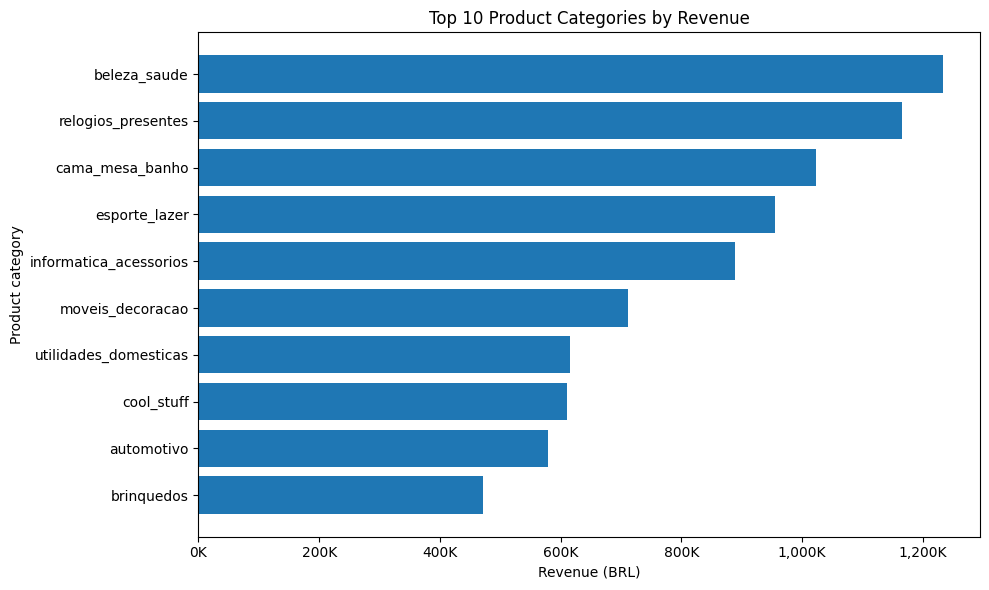

In [71]:
# BAR CHART: Top 10 product categories by revenue

top_cat = category_sales.head(10).sort_values()       # smallest first, so the largest ends up on top

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_cat.index, top_cat.values, color="#1f77b4")

ax.set_title("Top 10 Product Categories by Revenue")
ax.set_xlabel("Revenue (BRL)")
ax.set_ylabel("Product category")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:,.0f}K"))   # 1,200,000 shows as 1,200K

plt.tight_layout()
plt.savefig("../outputs/charts/revenue_by_category.png", dpi=300, bbox_inches="tight")   # save BEFORE show
plt.show()

**Interpretation** - Beleza_saude was the top category with 1,233,131.72 BRL (9.33% of revenue).
The top 10 categories have fairly similar revenue, so no single category dominates sales.

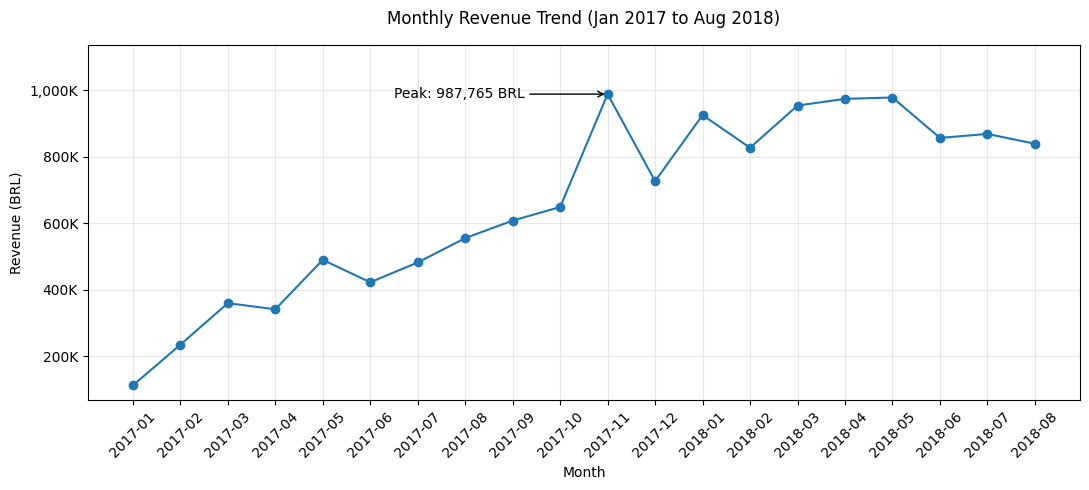

In [72]:
# LINE CHART: Monthly revenue trend (complete months only)

x = monthly_core.index.astype(str)
peak_month = str(monthly_core["revenue"].idxmax())
peak_value = monthly_core["revenue"].max()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, monthly_core["revenue"], marker="o", color="#1f77b4")

# Label placed to the LEFT of the peak, so it doesn't touch the title
ax.annotate(f"Peak: {peak_value:,.0f} BRL", xy=(peak_month, peak_value),
            xytext=(-60, 0), textcoords="offset points",
            ha="right", va="center",
            arrowprops=dict(arrowstyle="->"))

ax.set_ylim(top=peak_value * 1.15)          # extra space above the highest point

ax.set_title("Monthly Revenue Trend (Jan 2017 to Aug 2018)", pad=15)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (BRL)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y/1000:,.0f}K"))
plt.xticks(rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/charts/monthly_revenue_trend.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation** - Revenue rose steadily through 2017 and peaked in November 2017 at 987,765 BRL, coinciding with Black Friday. It fell 
26.5% in December, then stayed between about 826,000 and 978,000 BRL in 2018, so growth has levelled off.

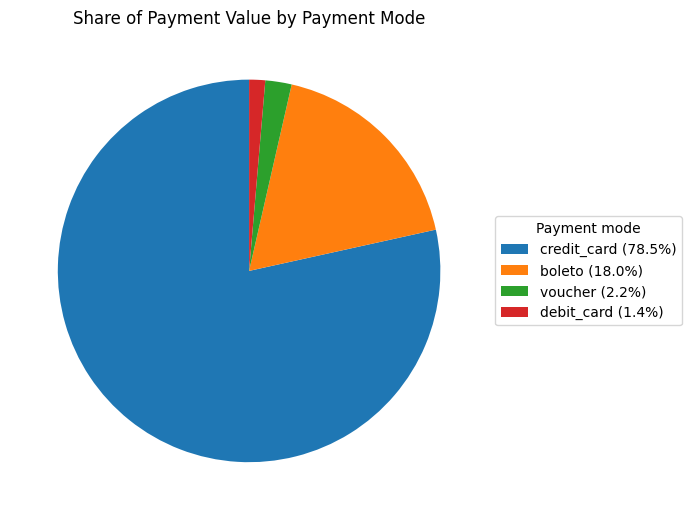

In [73]:
# PIE CHART: Share of payment value by payment mode (only 4 segments, so a pie is readable)

fig, ax = plt.subplots(figsize=(7, 7))
wedges, _ = ax.pie(payment_share.values, startangle=90)

# Legend with percentages avoids overlapping labels on the small slices
pct = payment_share / payment_share.sum() * 100
ax.legend(wedges, [f"{name} ({p:.1f}%)" for name, p in zip(payment_share.index, pct)],
          title="Payment mode", loc="center left", bbox_to_anchor=(1, 0.5))

ax.set_title("Share of Payment Value by Payment Mode")

plt.tight_layout()
plt.savefig("../outputs/charts/payment_mode_share.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation** - Credit cards made up 78.5% of payment value, followed by boleto (18.0%). Vouchers (2.2%) and debit cards (1.4%) are minor, so the business depends mainly on card payments.

### Dashboard Mockup

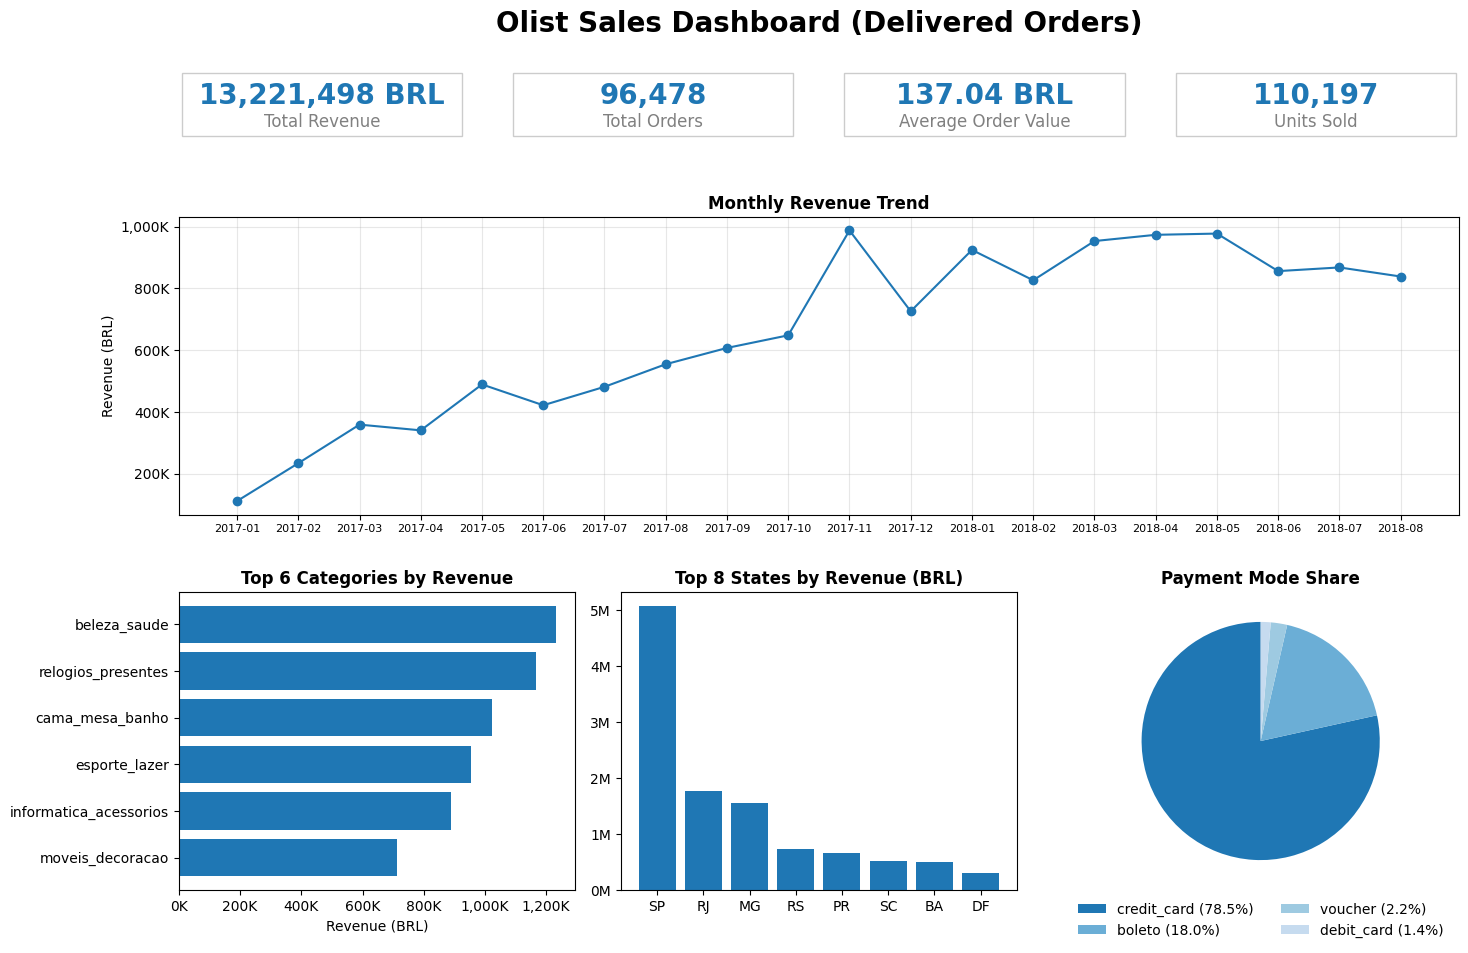

In [74]:
# DASHBOARD: KPI cards on top, trend chart in the centre, 3 charts below

fig = plt.figure(figsize=(16, 10))

# Grid with 3 rows and 12 columns. hspace/wspace = gaps between charts (smaller = tighter)
gs = fig.add_gridspec(3, 12, height_ratios=[0.7, 3, 3], hspace=0.35, wspace=0.7,
                      left=0.10, right=0.90, top=0.90, bottom=0.08)
fig.suptitle("Olist Sales Dashboard (Delivered Orders)", fontsize=20, fontweight="bold", y=0.96)

# 1) KPI cards: each card uses 3 of the 12 columns
kpis = [("Total Revenue", f"{total_revenue:,.0f} BRL"),
        ("Total Orders", f"{total_orders:,}"),
        ("Average Order Value", f"{average_order_value:,.2f} BRL"),
        ("Units Sold", f"{total_units_sold:,}")]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i*3:(i+1)*3])        # columns 0-3, 3-6, 6-9, 9-12
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0.01, 0.05), 0.98, 0.9, fill=False,
                               edgecolor="#cccccc", transform=ax.transAxes))
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=20, fontweight="bold", color="#1f77b4")
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=12, color="gray")

# 2) Trend chart (full width)
ax1 = fig.add_subplot(gs[1, :])
ax1.plot(monthly_core.index.astype(str), monthly_core["revenue"], marker="o", color="#1f77b4")
ax1.set_title("Monthly Revenue Trend", fontweight="bold")
ax1.set_ylabel("Revenue (BRL)")
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y/1000:,.0f}K"))
ax1.tick_params(axis="x", labelsize=8)               # small month labels, no rotation needed
ax1.grid(alpha=0.3)

# 3) Top 6 categories: BAR chart (horizontal), columns 0-4 of the bottom row
ax2 = fig.add_subplot(gs[2, 0:4])
cat = category_sales.head(6).sort_values()
ax2.barh(cat.index, cat.values, color="#1f77b4")
ax2.set_title("Top 6 Categories by Revenue", fontweight="bold")
ax2.set_xlabel("Revenue (BRL)")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:,.0f}K"))

# 4) Top 8 states: COLUMN chart (vertical), columns 4-8
ax3 = fig.add_subplot(gs[2, 4:8])
st = state_summary["revenue"].head(8)
ax3.bar(st.index, st.values, color="#1f77b4")
ax3.set_title("Top 8 States by Revenue (BRL)", fontweight="bold")
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y/1000000:.0f}M"))


# 5) Payment mode: PIE chart, columns 8-12
ax4 = fig.add_subplot(gs[2, 8:12])
colors = ["#1f77b4", "#6baed6", "#9ecae1", "#c6dbef"]
wedges, _ = ax4.pie(payment_share.values, startangle=90,
                colors=["#1f77b4", "#6baed6", "#9ecae1", "#c6dbef"])
pct = payment_share / payment_share.sum() * 100
ax4.legend(wedges, [f"{n} ({p:.1f}%)" for n, p in zip(payment_share.index, pct)],
           loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
ax4.set_title("Payment Mode Share", fontweight="bold")

plt.savefig("../outputs/dashboard/dashboard-mockup.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretation** -The dashboard combines the main KPIs (13.2M BRL revenue, 96,478 orders, 137.04 BRL average order value) with the monthly trend, top 6 categories, top 8 states and payment mix. Revenue peaked in November 2017, is spread fairly evenly across the top categories, is concentrated in a few states (SP alone is 38.33%), and is mostly paid by credit card (78.5%). All figures are for delivered orders, in BRL, excluding freight.